In [6]:
%pip install shap lime scikit-learn pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay)

RANDOM_STATE = 42
sns.set_style("whitegrid")

Load and clean Dataset

In [8]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")   # put the CSV next to the notebook
print(df.shape)

# TotalCharges has blank strings (new customers, tenure = 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


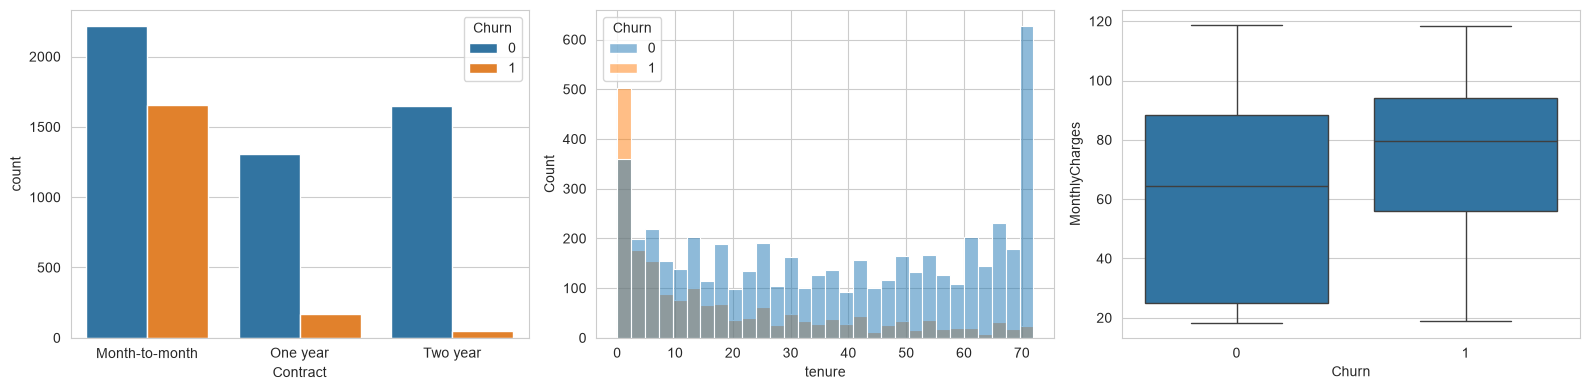

In [9]:
print(df["Churn"].value_counts(normalize=True).round(3))   # class imbalance (~26% churn)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="Contract", hue="Churn", ax=ax[0])
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=ax[1])
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax[2])
plt.tight_layout(); plt.show()

Feature Engineering

In [10]:
data = df.copy()
cust_ids = data["customerID"]
data = data.drop(columns=["customerID"])

service_cols = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
data["NumServices"]      = sum((data[c] == "Yes").astype(int) for c in service_cols)
data["NoSupportServices"] = ((data["OnlineSecurity"] != "Yes") & (data["TechSupport"] != "Yes")).astype(int)
data["AvgMonthlySpend"]  = data["TotalCharges"] / data["tenure"].replace(0, 1)
data["BillingSpike"]     = data["MonthlyCharges"] - data["AvgMonthlySpend"]   # >0 => paying more than historical average
data["IsMonthToMonth"]   = (data["Contract"] == "Month-to-month").astype(int)
data["AutoPay"]          = data["PaymentMethod"].str.contains("automatic").astype(int)
data["NewCustomer"]      = (data["tenure"] <= 6).astype(int)

X = data.drop(columns="Churn")
y = data["Churn"]

num_cols = ["tenure","MonthlyCharges","TotalCharges","NumServices","AvgMonthlySpend","BillingSpike"]
cat_cols = X.select_dtypes(exclude="number").columns.tolist()   # text columns
bin_cols = [c for c in X.columns if c not in num_cols + cat_cols]   # already 0/1 columns
print(len(num_cols), len(cat_cols), len(bin_cols))

6 15 5


Train / test split & preprocessing

In [11]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, cust_ids, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols),
    ("bin", "passthrough", bin_cols),
])
Xtr = pre.fit_transform(X_train)
Xte = pre.transform(X_test)
feature_names = [n.split("__")[1] for n in pre.get_feature_names_out()]
print(Xtr.shape, Xte.shape)

(5634, 47) (1409, 47)


Base models + Stacked ensemble

In [12]:
lr  = LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
dt  = DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight="balanced", random_state=RANDOM_STATE)
rf  = RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=5,
                             class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
gb  = GradientBoostingClassifier(n_estimators=250, learning_rate=0.05, max_depth=3,
                                 subsample=0.8, random_state=RANDOM_STATE)

stack = StackingClassifier(
    estimators=[("lr", lr), ("dt", dt), ("rf", rf), ("gb", gb)],
    final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced"),
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    stack_method="predict_proba", n_jobs=-1)

models = {"Logistic Regression": lr, "Decision Tree": dt, "Random Forest": rf,
          "Gradient Boosting": gb, "STACKED ENSEMBLE": stack}
for name, m in models.items():
    m.fit(Xtr, y_train)
print("All models trained")

All models trained


Evaluation (default 0.5 threshold)

In [13]:
rows = []
for name, m in models.items():
    p = m.predict_proba(Xte)[:, 1]; pred = (p >= 0.5).astype(int)
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred),
                 recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, p)])
results = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1","ROC-AUC"]).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.747,0.516,0.799,0.627,0.846
Decision Tree,0.757,0.530,0.749,0.621,0.832
Random Forest,0.761,0.533,0.797,0.639,0.842
Gradient Boosting,0.805,0.671,0.519,0.585,0.843
STACKED ENSEMBLE,0.752,0.522,0.786,0.628,0.847


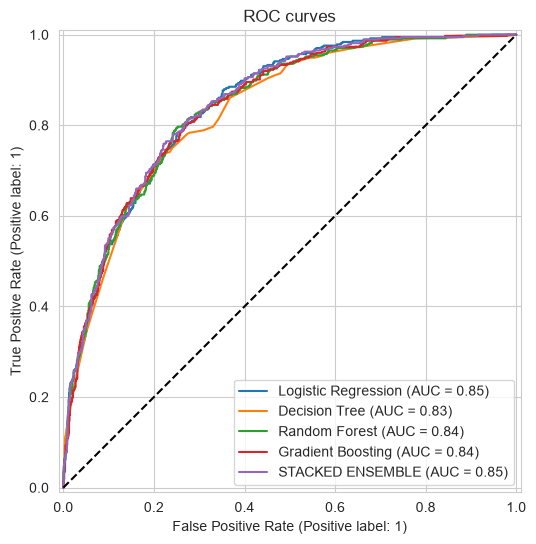

In [14]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, Xte, y_test, name=name, ax=ax)
ax.plot([0,1],[0,1],"k--"); ax.set_title("ROC curves"); plt.show()

Threshold tuning (important for churn)

Best threshold = 0.64
              precision    recall  f1-score   support

        Stay       0.88      0.82      0.85      1035
       Churn       0.58      0.68      0.63       374

    accuracy                           0.78      1409
   macro avg       0.73      0.75      0.74      1409
weighted avg       0.80      0.78      0.79      1409

ROC-AUC: 0.847


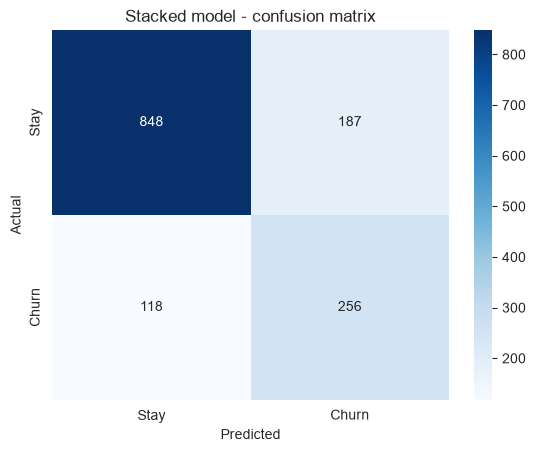

In [15]:
oof = cross_val_predict(stack, Xtr, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=1),
                        method="predict_proba")[:, 1]
ths = np.arange(0.2, 0.8, 0.01)
f1s = [f1_score(y_train, oof >= t) for t in ths]
best_t = ths[int(np.argmax(f1s))]
print(f"Best threshold = {best_t:.2f}")

p_stack = stack.predict_proba(Xte)[:, 1]
pred = (p_stack >= best_t).astype(int)
print(classification_report(y_test, pred, target_names=["Stay","Churn"]))
print("ROC-AUC:", round(roc_auc_score(y_test, p_stack), 3))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stay","Churn"], yticklabels=["Stay","Churn"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Stacked model - confusion matrix"); plt.show()

SHAP - global explanation

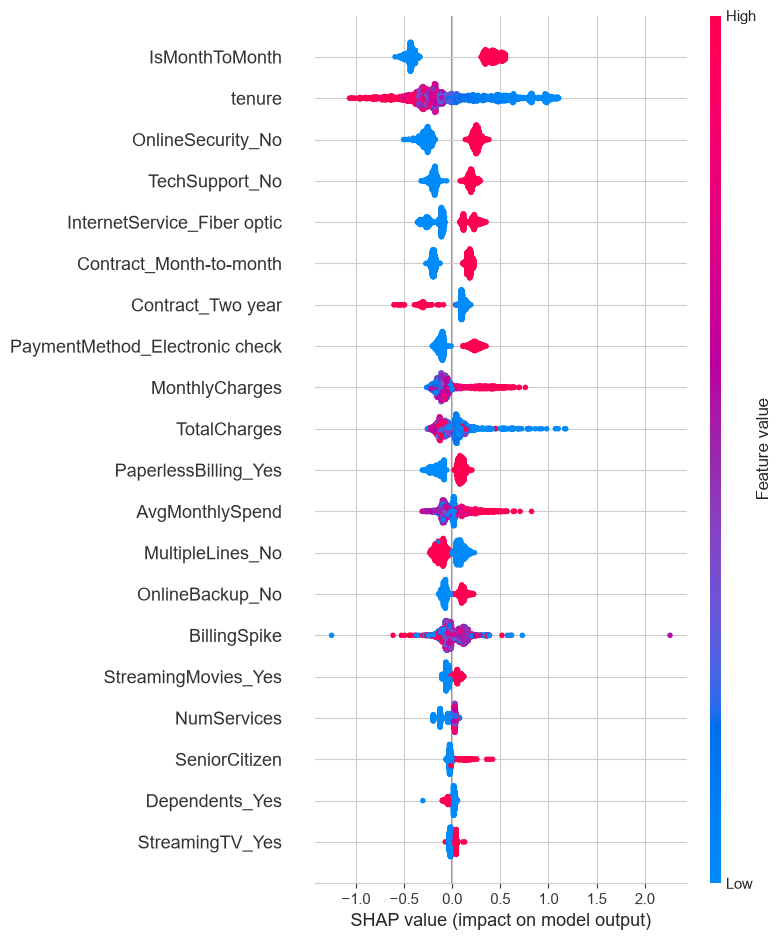

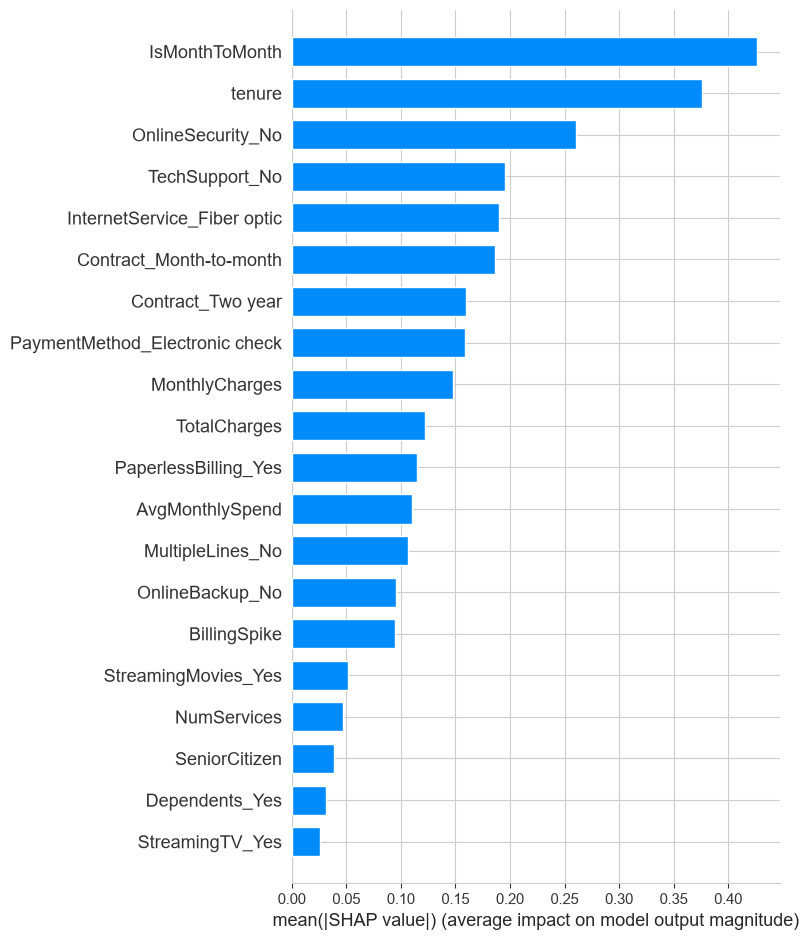

In [16]:
import shap
Xte_df = pd.DataFrame(Xte, columns=feature_names)

explainer = shap.TreeExplainer(gb)
shap_values = explainer.shap_values(Xte_df)

shap.summary_plot(shap_values, Xte_df, show=True)                       # beeswarm
shap.summary_plot(shap_values, Xte_df, plot_type="bar", show=True)      # mean |SHAP|

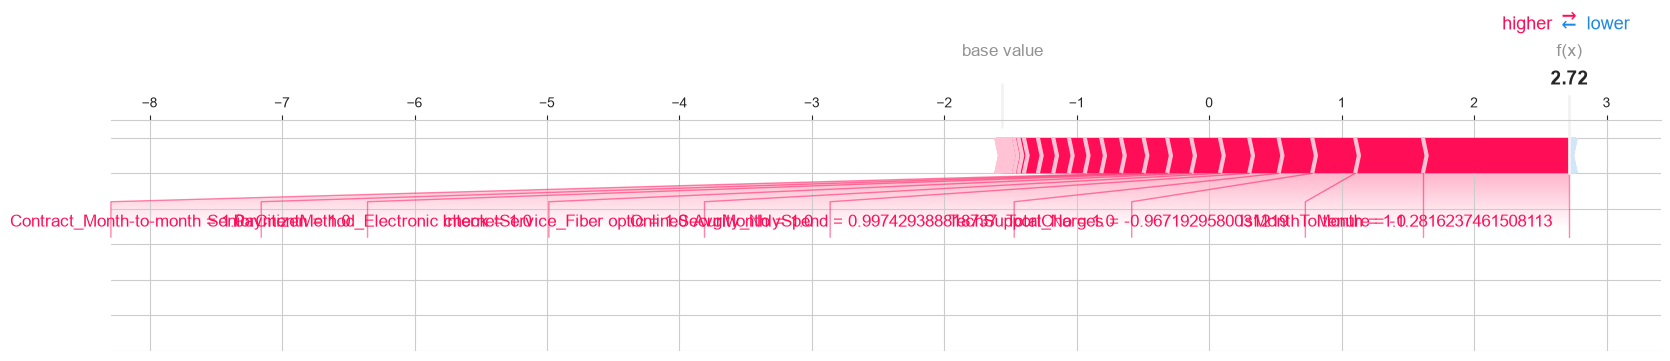

In [17]:
i = int(np.argmax(p_stack))
shap.force_plot(explainer.expected_value, shap_values[i], Xte_df.iloc[i], matplotlib=True)

LIME - top-3 churn drivers per at-risk customer

In [18]:
from lime.lime_tabular import LimeTabularExplainer

lime_exp = LimeTabularExplainer(
    training_data=Xtr, feature_names=feature_names,
    class_names=["Stay","Churn"], mode="classification",
    discretize_continuous=False, random_state=RANDOM_STATE)

def top3_drivers(row):
    exp = lime_exp.explain_instance(row, stack.predict_proba, num_features=8, num_samples=2000)
    # keep only features pushing TOWARDS churn (positive weight)
    drivers = [(f, w) for f, w in exp.as_list(label=1) if w > 0][:3]
    return drivers

def risk_tier(p):
    return "HIGH" if p >= 0.7 else "MEDIUM" if p >= best_t else "LOW"

Customer-level retention dashboard

In [19]:
N_TOP = 15      # increase for more customers (each takes ~1 sec)

dash = pd.DataFrame({"customerID": id_test.values, "ChurnProb": p_stack,
                     "Contract": X_test["Contract"].values,
                     "MonthlyCharges": X_test["MonthlyCharges"].values,
                     "Tenure": X_test["tenure"].values})
dash["Risk"] = dash["ChurnProb"].apply(risk_tier)
at_risk = dash[dash["ChurnProb"] >= best_t].sort_values("ChurnProb", ascending=False).head(N_TOP)

rows = []
for idx in at_risk.index:
    drv = top3_drivers(Xte[idx])
    r = at_risk.loc[idx].to_dict()
    for k in range(3):
        r[f"Driver_{k+1}"] = f"{drv[k][0]} (+{drv[k][1]:.2f})" if k < len(drv) else "-"
    rows.append(r)
dashboard = pd.DataFrame(rows)
dashboard["ChurnProb"] = dashboard["ChurnProb"].round(3)
print(f"{(dash['ChurnProb'] >= best_t).sum()} at-risk customers in test set; showing top {N_TOP}")
dashboard

443 at-risk customers in test set; showing top 15


,customerID,ChurnProb,Contract,MonthlyCharges,Tenure,Risk,Driver_1,Driver_2,Driver_3
0,5178-LMXOP,0.926,Month-to-month,95.10,1,HIGH,InternetService_Fiber optic (+0.05),IsMonthToMonth (+0.05),NewCustomer (+0.04)
1,0295-PPHDO,0.925,Month-to-month,95.45,1,HIGH,IsMonthToMonth (+0.05),InternetService_Fiber optic (+0.05),Contract_Month-to-month (+0.04)
2,1069-XAIEM,0.922,Month-to-month,85.05,1,HIGH,IsMonthToMonth (+0.06),InternetService_Fiber optic (+0.05),NewCustomer (+0.04)
3,9057-SIHCH,0.919,Month-to-month,96.60,3,HIGH,IsMonthToMonth (+0.05),InternetService_Fiber optic (+0.05),Contract_Month-to-month (+0.04)
4,9248-OJYKK,0.919,Month-to-month,76.45,1,HIGH,IsMonthToMonth (+0.05),InternetService_Fiber optic (+0.05),NewCustomer (+0.04)
5,2545-EBUPK,0.918,Month-to-month,84.05,2,HIGH,IsMonthToMonth (+0.05),InternetService_Fiber optic (+0.05),Contract_Month-to-month (+0.04)
6,0970-ETWGE,0.916,Month-to-month,89.55,1,HIGH,IsMonthToMonth (+0.05),InternetService_Fiber optic (+0.05),Contract_Month-to-month (+0.04)
7,3722-WPXTK,0.916,Month-to-month,88.35,1,HIGH,IsMonthToMonth (+0.05),InternetService_Fiber optic (+0.05),NewCustomer (+0.04)
8,2609-IAICY,0.915,Month-to-month,77.15,1,HIGH,IsMonthToMonth (+0.05),InternetService_Fiber optic (+0.05),Contract_Month-to-month (+0.04)
9,4750-ZRXIU,0.914,Month-to-month,84.60,4,HIGH,IsMonthToMonth (+0.05),InternetService_Fiber optic (+0.05),Contract_Month-to-month (+0.04)


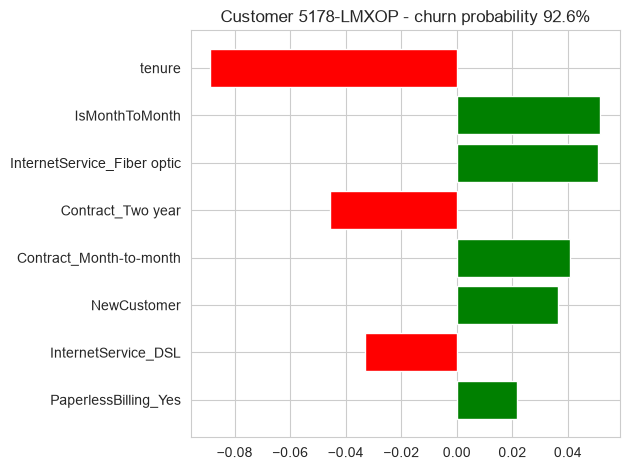

In [21]:
# Visual card for the single highest-risk customer
cid = dashboard.iloc[0]["customerID"]
idx = np.where(id_test.values == cid)[0][0]
exp = lime_exp.explain_instance(Xte[idx], stack.predict_proba, num_features=8, num_samples=3000)
fig = exp.as_pyplot_figure(label=1)
plt.title(f"Customer {cid} - churn probability {p_stack[idx]:.1%}")
plt.tight_layout(); plt.show()

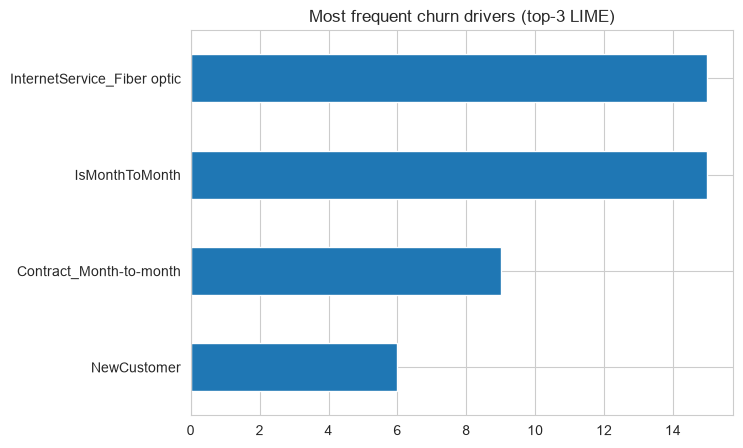

In [22]:
from collections import Counter
c = Counter()
for col in ["Driver_1","Driver_2","Driver_3"]:
    c.update(dashboard[col].str.split(" \\(").str[0])
pd.Series(c).sort_values().plot(kind="barh", figsize=(7,5), title="Most frequent churn drivers (top-3 LIME)")
plt.show()

dashboard.to_csv("retention_dashboard.csv", index=False)   # hand this to the retention team